<a href="https://colab.research.google.com/github/AnjalyKuriakose98/fake-news-detection-NLP/blob/main/Week2_Model_Training_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load cleaned dataset from Week 1
df = pd.read_csv("/content/cleaned_news.csv")

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

df.head()

Dataset shape: (44689, 4)
Columns: ['title', 'text', 'label', 'processed_text']


,title,text,label,processed_text
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,0,donald trump sends embarrassing new year eve m...
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,0,drunk bragging trump staffer started russian c...
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",0,sheriff david clarke becomes internet joke thr...
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",0,trump obsessed even obama name coded website i...
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,0,pope francis called donald trump christmas spe...


In [8]:
print("Class distribution:")
print(df["label"].value_counts())

print("\nMissing processed text:")
print(df["processed_text"].isnull().sum())

Class distribution:
label
0    23478
1    21211
Name: count, dtype: int64

Missing processed text:
9


In [9]:
X = df["processed_text"]      # X means the input which contains news text
y = df["label"]               # Y means target and contains the classification

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (44689,)
y shape: (44689,)


In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,   # Using 20% dataset for testing
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 35751
Testing samples: 8938


In [11]:
# Check missing values
print("Missing values in X_train:", X_train.isnull().sum())
print("Missing values in X_test:", X_test.isnull().sum())

Missing values in X_train: 6
Missing values in X_test: 3


In [12]:
# Replace missing text with empty strings
X_train = X_train.fillna("")
X_test = X_test.fillna("")

print("Missing X_train:", X_train.isnull().sum())
print("Missing X_test:", X_test.isnull().sum())

Missing X_train: 0
Missing X_test: 0


In [13]:
from sklearn.feature_extraction.text import TfidfVectorizer   #It converts text into numerical representations based on the data.

tfidf = TfidfVectorizer(
    max_features=10000,   #limits feature vocabulary to atmost
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (35751, 10000)
Testing TF-IDF shape: (8938, 10000)


In [14]:
from sklearn.linear_model import LogisticRegression  # Model training
from sklearn.metrics import accuracy_score

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train model
lr_model.fit(X_train_tfidf, y_train)

# Make predictions
lr_predictions = lr_model.predict(X_test_tfidf)

# Calculate accuracy
lr_accuracy = accuracy_score(y_test, lr_predictions)

print("Logistic Regression Accuracy:", round(lr_accuracy, 4))
print("Accuracy Percentage:", round(lr_accuracy * 100, 2), "%")

Logistic Regression Accuracy: 0.9916
Accuracy Percentage: 99.16 %


In [15]:
from sklearn.naive_bayes import MultinomialNB   #naive bayes is probabilistic classifier  used for text classification

nb_model = MultinomialNB()

# Train model
nb_model.fit(X_train_tfidf, y_train)

# Prediction
nb_predictions = nb_model.predict(X_test_tfidf)

# Accuracy
nb_accuracy = accuracy_score(y_test, nb_predictions)

print("Naive Bayes Accuracy:", round(nb_accuracy, 4))
print("Accuracy Percentage:", round(nb_accuracy * 100, 2), "%")

Naive Bayes Accuracy: 0.9493
Accuracy Percentage: 94.93 %


In [16]:
from sklearn.svm import LinearSVC    # Vector machine, Here used linear SVC and find a decision boundary separating the classes in the feature space.

svm_model = LinearSVC(
    random_state=42
)

# Train model
svm_model.fit(X_train_tfidf, y_train)

# Prediction
svm_predictions = svm_model.predict(X_test_tfidf)

# Accuracy
svm_accuracy = accuracy_score(y_test, svm_predictions)

print("SVM Accuracy:", round(svm_accuracy, 4))
print("Accuracy Percentage:", round(svm_accuracy * 100, 2), "%")

SVM Accuracy: 0.9966
Accuracy Percentage: 99.66 %


In [17]:
results = pd.DataFrame({                  #compairing above 3 models
    "Model": [
        "Logistic Regression",
        "Naive Bayes",
        "SVM"
    ],

    "Accuracy": [
        lr_accuracy,
        nb_accuracy,
        svm_accuracy
    ]
})

results["Accuracy (%)"] = results["Accuracy"] * 100

results

,Model,Accuracy,Accuracy (%)
0,Logistic Regression,0.991609,99.160886
1,Naive Bayes,0.949318,94.931752
2,SVM,0.996644,99.664354


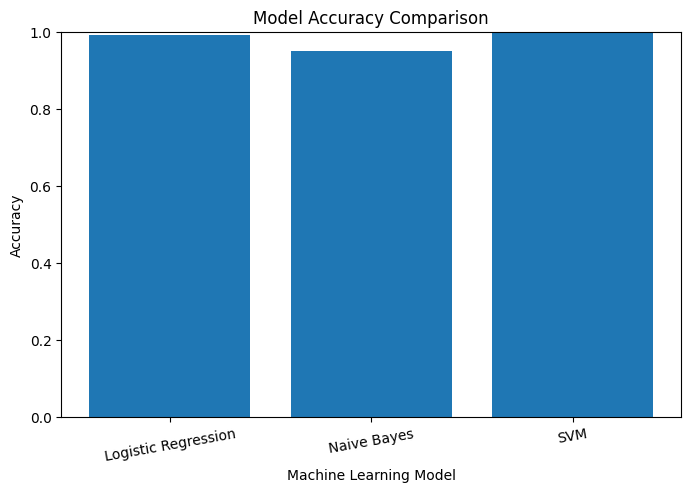

In [18]:
plt.figure(figsize=(8, 5))       #graph for accuracy

plt.bar(
    results["Model"],
    results["Accuracy"]
)

plt.title("Model Accuracy Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1)

plt.xticks(rotation=10)

plt.show()

In [19]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score       #Combines precision and recall into one measure.
)

evaluation = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Naive Bayes",
        "SVM"
    ],

    "Accuracy": [
        accuracy_score(y_test, lr_predictions),
        accuracy_score(y_test, nb_predictions),
        accuracy_score(y_test, svm_predictions)
    ],

    "Precision": [
        precision_score(y_test, lr_predictions),
        precision_score(y_test, nb_predictions),
        precision_score(y_test, svm_predictions)
    ],

    "Recall": [
        recall_score(y_test, lr_predictions),
        recall_score(y_test, nb_predictions),
        recall_score(y_test, svm_predictions)
    ],

    "F1 Score": [
        f1_score(y_test, lr_predictions),
        f1_score(y_test, nb_predictions),
        f1_score(y_test, svm_predictions)
    ]
})

evaluation.round(4)

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.9916,0.9890,0.9934,0.9912
1,Naive Bayes,0.9493,0.9440,0.9496,0.9468
2,SVM,0.9966,0.9969,0.9960,0.9965


In [20]:
fake_evaluation = pd.DataFrame({     # Evaluating Fake news
    "Model": [
        "Logistic Regression",
        "Naive Bayes",
        "SVM"
    ],

    "Fake Precision": [
        precision_score(y_test, lr_predictions, pos_label=0),
        precision_score(y_test, nb_predictions, pos_label=0),
        precision_score(y_test, svm_predictions, pos_label=0)
    ],

    "Fake Recall": [
        recall_score(y_test, lr_predictions, pos_label=0),
        recall_score(y_test, nb_predictions, pos_label=0),
        recall_score(y_test, svm_predictions, pos_label=0)
    ],

    "Fake F1": [
        f1_score(y_test, lr_predictions, pos_label=0),
        f1_score(y_test, nb_predictions, pos_label=0),
        f1_score(y_test, svm_predictions, pos_label=0)
    ]
})

fake_evaluation.round(4)

,Model,Fake Precision,Fake Recall,Fake F1
0,Logistic Regression,0.9940,0.9900,0.9920
1,Naive Bayes,0.9542,0.9491,0.9516
2,SVM,0.9964,0.9972,0.9968


In [21]:
from sklearn.metrics import classification_report

print("SVM Classification Report:\n")

print(
    classification_report(
        y_test,
        svm_predictions,
        target_names=["Fake", "Real"]
    )
)

SVM Classification Report:

              precision    recall  f1-score   support

        Fake       1.00      1.00      1.00      4696
        Real       1.00      1.00      1.00      4242

    accuracy                           1.00      8938
   macro avg       1.00      1.00      1.00      8938
weighted avg       1.00      1.00      1.00      8938



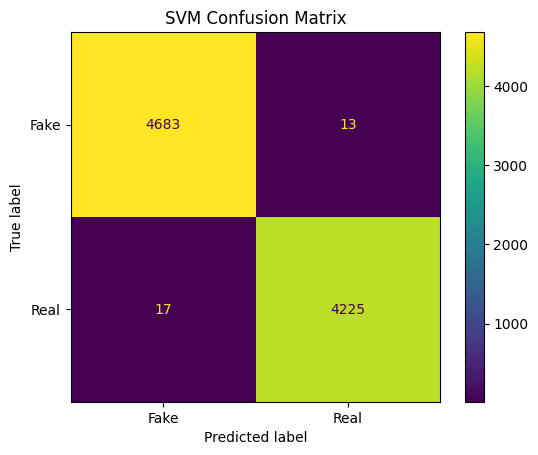

In [22]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    svm_predictions,      # converts the numeric class into something understandable for the user.
    display_labels=["Fake", "Real"]
)

plt.title("SVM Confusion Matrix")
plt.show()

In [23]:
best_index = evaluation["F1 Score"].idxmax()

print("Highest F1 model:")
print(evaluation.loc[best_index])

Highest F1 model:
Model             SVM
Accuracy     0.996644
Precision    0.996933
Recall       0.995992
F1 Score     0.996462
Name: 2, dtype: object


In [24]:
import re
import nltk

from nltk.corpus import stopwords

nltk.download("stopwords")

stop_words = set(stopwords.words("english"))

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [25]:
def preprocess_news(text):

    # Lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", "", text)

    # Remove numbers, punctuation and special characters
    text = re.sub(r"[^a-zA-Z\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    # Remove stop words
    words = text.split()

    words = [
        word for word in words
        if word not in stop_words
    ]

    return " ".join(words)

In [26]:
def predict_news(article):

    # Check empty input
    if not article.strip():
        return "Please enter a news article."

    # Preprocess
    cleaned_article = preprocess_news(article)

    # TF-IDF transformation
    article_tfidf = tfidf.transform([cleaned_article])

    # Prediction
    prediction = svm_model.predict(article_tfidf)[0]

    if prediction == 0:
        return "Potentially FAKE News"
    else:
        return "Predicted REAL News"

In [27]:
article = input("Enter a news article: ")

result = predict_news(article)

print("\nPrediction:", result)

Enter a news article: NASA confirms that Earth will experience 15 days of complete darkness next month.  Copy text

Prediction: Predicted REAL News


In [28]:
import joblib

joblib.dump(
    svm_model,
    "/content/fake_news_model.pkl"
)

joblib.dump(
    tfidf,
    "/content/tfidf_vectorizer.pkl"
)

print("Model and TF-IDF vectorizer saved successfully!")

Model and TF-IDF vectorizer saved successfully!


In [29]:
import os

print(os.listdir("/content"))

['.config', 'tfidf_vectorizer.pkl', 'fake_news_model.pkl', '.ipynb_checkpoints', 'cleaned_news.csv', 'sample_data']


In [30]:
print("SVM Model:", "svm_model" in globals())
print("TF-IDF Vectorizer:", "tfidf" in globals())

SVM Model: True
TF-IDF Vectorizer: True


In [32]:
from google.colab import drive    #saved to google cloud

drive.mount('/content/drive')

Mounted at /content/drive


In [33]:
from google.colab import files

files.download('/content/fake_news_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [34]:
files.download('/content/tfidf_vectorizer.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [35]:
files.download('/content/cleaned_news.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [36]:
!pip install -q gradio

In [37]:
import gradio as gr

def detect_news(article):
    if not article.strip():
        return "Please enter a news article."

    return predict_news(article)

demo = gr.Interface(
    fn=detect_news,
    inputs=gr.Textbox(
        lines=8,
        label="Enter News Article",
        placeholder="Paste your news article here..."
    ),
    outputs=gr.Textbox(label="Prediction Result"),
    title="Fake News Detection System",
    description="Fake News Detection using NLP, TF-IDF and SVM"
)

demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://9313cfa55256c9eab1.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [38]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix #model evaluation

y_pred = svm_model.predict(X_test_tfidf)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.9966435444170956

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      4696
           1       1.00      1.00      1.00      4242

    accuracy                           1.00      8938
   macro avg       1.00      1.00      1.00      8938
weighted avg       1.00      1.00      1.00      8938


Confusion Matrix:
[[4683   13]
 [  17 4225]]


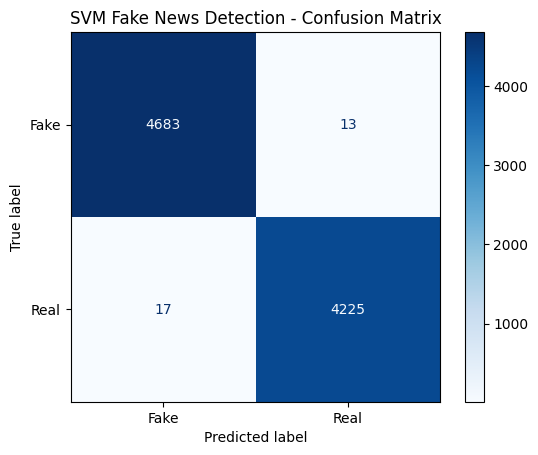

In [39]:
import matplotlib.pyplot as plt #confusion graph matrix
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Fake", "Real"],
    cmap="Blues"
)

plt.title("SVM Fake News Detection - Confusion Matrix")
plt.savefig("confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

In [41]:
print(df.columns.tolist())

['title', 'text', 'label', 'processed_text']


In [42]:
X = df["processed_text"].fillna("")
y = df["label"]

print("Total articles:", len(X))
print("Labels:", y.value_counts())

Total articles: 44689
Labels: label
0    23478
1    21211
Name: count, dtype: int64


In [43]:
variables = [
    "X_train",
    "X_test",
    "y_train",
    "y_test",
    "X_train_tfidf",
    "X_test_tfidf",
    "tfidf",
    "svm_model"
]

for name in variables:
    print(name, ":", name in globals())

X_train : True
X_test : True
y_train : True
y_test : True
X_train_tfidf : True
X_test_tfidf : True
tfidf : True
svm_model : True


In [44]:
from sklearn.model_selection import train_test_split  #checking data leakage
from sklearn.feature_extraction.text import TfidfVectorizer

X_train, X_test, y_train, y_test = train_test_split(
    df["processed_text"].fillna(""),
    df["label"],
    test_size=0.2,
    random_state=42,
    stratify=df["label"]
)

tfidf = TfidfVectorizer(max_features=5000)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training data:", X_train_tfidf.shape)
print("Testing data:", X_test_tfidf.shape)

Training data: (35751, 5000)
Testing data: (8938, 5000)


In [45]:
print("Total articles:", len(df))

print(
    "Duplicate processed articles:",
    df["processed_text"].duplicated().sum()
)

print(
    "Missing processed text:",
    df["processed_text"].isnull().sum()
)

Total articles: 44689
Duplicate processed articles: 5862
Missing processed text: 9


In [46]:
train_texts = set(X_train.dropna())
test_texts = set(X_test.dropna())

common_articles = train_texts.intersection(test_texts)

print(
    "Articles appearing in both training and testing:",
    len(common_articles)
)

Articles appearing in both training and testing: 1819


In [47]:
import pandas as pd

# Create a new copy of the dataset
df_clean = df.copy()

# Remove missing text
df_clean = df_clean.dropna(subset=["processed_text"])

# Remove empty articles
df_clean = df_clean[
    df_clean["processed_text"].str.strip() != ""
]

# Check conflicting labels for identical text
conflicts = (
    df_clean.groupby("processed_text")["label"]
    .nunique()
)

conflicting_texts = conflicts[conflicts > 1].index

print("Conflicting article texts:", len(conflicting_texts))

# Exclude conflicting examples
df_clean = df_clean[
    ~df_clean["processed_text"].isin(conflicting_texts)
]

# Remove duplicate articles
df_clean = df_clean.drop_duplicates(
    subset=["processed_text"]
).reset_index(drop=True)

print("Cleaned dataset size:", df_clean.shape)
print("Remaining duplicates:",
      df_clean["processed_text"].duplicated().sum())

Conflicting article texts: 0
Cleaned dataset size: (38826, 4)
Remaining duplicates: 0


In [48]:
from sklearn.model_selection import train_test_split

X = df_clean["processed_text"]
y = df_clean["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training articles:", len(X_train))
print("Testing articles:", len(X_test))

common_articles = set(X_train).intersection(set(X_test))

print("Overlapping articles:", len(common_articles))

Training articles: 31060
Testing articles: 7766
Overlapping articles: 0


In [49]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=5000)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training features:", X_train_tfidf.shape)
print("Testing features:", X_test_tfidf.shape)

Training features: (31060, 5000)
Testing features: (7766, 5000)


In [50]:
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

svm_model = LinearSVC(random_state=42)

svm_model.fit(X_train_tfidf, y_train)

y_pred = svm_model.predict(X_test_tfidf)

accuracy = accuracy_score(y_test, y_pred)

print("New SVM Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

New SVM Accuracy: 99.42 %

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      3580
           1       0.99      1.00      0.99      4186

    accuracy                           0.99      7766
   macro avg       0.99      0.99      0.99      7766
weighted avg       0.99      0.99      0.99      7766


Confusion Matrix:
[[3554   26]
 [  19 4167]]


In [51]:
import joblib #saving

joblib.dump(svm_model, "/content/fake_news_model_v2.pkl")
joblib.dump(tfidf, "/content/tfidf_vectorizer_v2.pkl")

print("Corrected SVM model saved successfully!")

Corrected SVM model saved successfully!


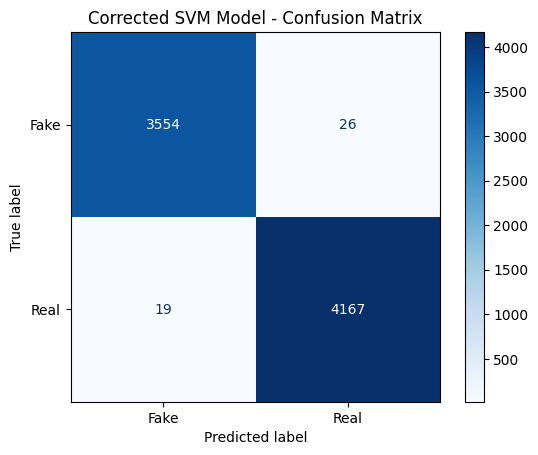

In [52]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Fake", "Real"],
    cmap="Blues"
)

plt.title("Corrected SVM Model - Confusion Matrix")
plt.savefig(
    "/content/confusion_matrix_v2.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [53]:
from sklearn.metrics import classification_report

report = classification_report(
    y_test,
    y_pred,
    target_names=["Fake", "Real"]
)

with open("/content/model_results_v2.txt", "w") as f:
    f.write("Fake News Detection - Corrected SVM Model\n")
    f.write("Accuracy: 99.42%\n\n")
    f.write(report)

print("Evaluation report saved!")

Evaluation report saved!


In [54]:
from google.colab import files

files.download("/content/fake_news_model_v2.pkl")
files.download("/content/tfidf_vectorizer_v2.pkl")
files.download("/content/confusion_matrix_v2.png")
files.download("/content/model_results_v2.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [55]:
import joblib

svm_model_v2 = joblib.load("/content/fake_news_model_v2.pkl")
tfidf_v2 = joblib.load("/content/tfidf_vectorizer_v2.pkl")

print("Corrected model loaded successfully!")

Corrected model loaded successfully!


In [56]:
def predict_news_v2(article):
    if not article or not article.strip():
        return "Please enter a news article."

    cleaned = preprocess_text(article)

    vector = tfidf_v2.transform([cleaned])

    prediction = svm_model_v2.predict(vector)[0]

    if prediction == 0:
        return "Potentially FAKE News"
    else:
        return "Predicted REAL News"

In [57]:
import gradio as gr

demo_v2 = gr.Interface(
    fn=predict_news_v2,
    inputs=gr.Textbox(
        lines=8,
        label="Enter News Article",
        placeholder="Paste a news article here..."
    ),
    outputs=gr.Textbox(label="Prediction Result"),
    title="Fake News Detection System - Version 2",
    description="NLP + TF-IDF + SVM | Duplicate-cleaned training data"
)

demo_v2.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://b96877b78db3181329.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [60]:
def predict_news_v2(article):

    if not article or not article.strip():
        return "Please enter a news article."

    # Use the original preprocessing function
    cleaned = preprocess_news(article)

    # Convert text to TF-IDF features
    vector = tfidf_v2.transform([cleaned])

    # Predict using corrected SVM model
    prediction = svm_model_v2.predict(vector)[0]

    if prediction == 0:
        return "Potentially FAKE News"
    else:
        return "Predicted REAL News"

In [61]:
news = """
Scientists confirm that drinking only chocolate
milk makes humans live for 200 years.
"""

result = predict_news_v2(news)

print("Prediction:", result)

Prediction: Potentially FAKE News


In [ ]:
import gradio as gr

demo_v2.close()

demo_v2 = gr.Interface(
    fn=predict_news_v2,
    inputs=gr.Textbox(
        lines=8,
        label="Enter News Article",
        placeholder="Paste your news article here..."
    ),
    outputs=gr.Textbox(label="Prediction Result"),
    title="Fake News Detection System - Version 2",
    description="Fake News Detection using NLP, TF-IDF and SVM"
)

demo_v2.launch(debug=True)

Closing server running on port: 7861
It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://d19d6f7dc83018f8df.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
